## Target and cohort selection

The goal is to answer three questions:
1. Which loan statuses can be reliably labeled 0 and 1?
2. How many usable loans remain each year?
3. Are newer loans biased because they haven't finished repayment?


In [1]:
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Change this if your raw CSV is stored somewhere else
CSV_PATH = ROOT / "data/raw/LendingClub_2007_to_2018Q4.csv"

OUTPUT_DIR = ROOT / "outputs/results"
FIGURE_DIR = ROOT / "outputs/figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

assert CSV_PATH.exists(), f"File not found: {CSV_PATH}"

print("Dataset:", CSV_PATH.name)
print("Size (GB):", round(CSV_PATH.stat().st_size / 1e9, 2))

Dataset: LendingClub_2007_to_2018Q4.csv
Size (GB): 1.68


In [2]:
status_counts = Counter()
cohort_counts = Counter()

total_rows = 0

for chunk in pd.read_csv(
    CSV_PATH,
    usecols=["loan_status", "issue_d", "term"],
    dtype=str,
    chunksize=100_000
):
    total_rows += len(chunk)

    chunk["loan_status"] = chunk["loan_status"].str.strip()

    status_counts.update(
        chunk["loan_status"].fillna("MISSING").value_counts().to_dict()
    )

    chunk["issue_year"] = pd.to_datetime(
        chunk["issue_d"].str.strip(),
        format="%b-%Y",
        errors="coerce"
    ).dt.year

    chunk["term_months"] = pd.to_numeric(
        chunk["term"].str.extract(r"(\d+)", expand=False),
        errors="coerce"
    )

    valid = chunk.dropna(
        subset=["issue_year", "term_months", "loan_status"]
    )

    grouped = valid.groupby(
        ["issue_year", "term_months", "loan_status"]
    ).size()

    cohort_counts.update(grouped.to_dict())

print("Total rows:", f"{total_rows:,}")

status_df = pd.DataFrame(
    status_counts.items(),
    columns=["loan_status", "count"]
)

status_df["percentage"] = (
    status_df["count"] / total_rows * 100
)

display(status_df.sort_values("count", ascending=False).round(2))

status_df.to_csv(
    OUTPUT_DIR / "loan_status_summary.csv",
    index=False
)

Total rows: 2,260,701


,loan_status,count,percentage
0,Fully Paid,1076751,47.63
2,Current,878317,38.85
1,Charged Off,268559,11.88
3,Late (31-120 days),21467,0.95
4,In Grace Period,8436,0.37
5,Late (16-30 days),4349,0.19
8,Does not meet the credit policy. Status:Fully ...,1988,0.09
9,Does not meet the credit policy. Status:Charge...,761,0.03
6,Default,40,0.00
7,MISSING,33,0.00


,total,fully_paid,charged_off,current,strict_resolved,resolved_pct,default_rate_resolved_pct
issue_year,,,,,,,
2007,603,206,45,0,251,41.63,17.93
2008,2393,1315,247,0,1562,65.27,15.81
2009,5281,4122,594,0,4716,89.30,12.60
2010,12537,10049,1487,0,11536,92.02,12.89
2011,21721,18424,3297,0,21721,100.00,15.18
2012,53367,44723,8644,0,53367,100.00,16.20
2013,134814,113780,21024,6,134804,99.99,15.60
2014,235629,181941,41161,11919,223102,94.68,18.45
2015,421095,299742,75803,43299,375545,89.18,20.18


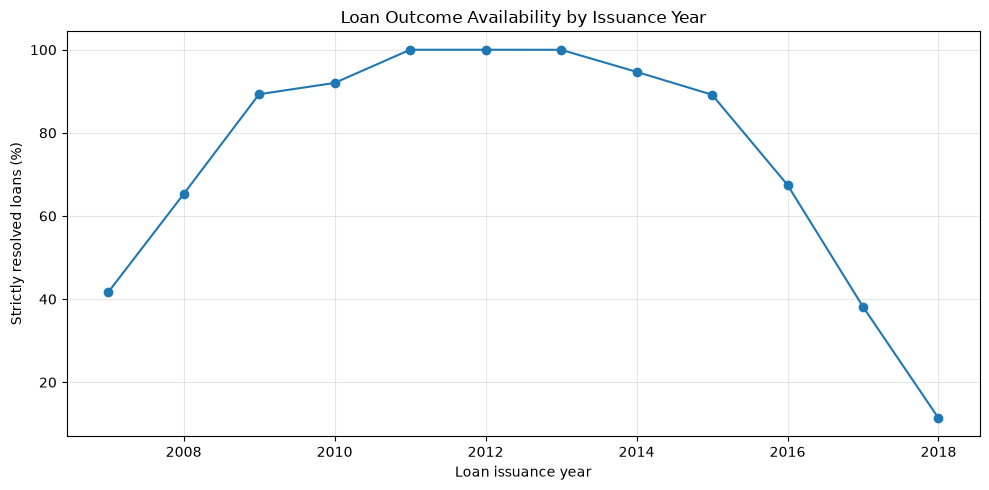

In [3]:
cohort_df = pd.DataFrame(
    [
        (year, term, status, count)
        for (year, term, status), count in cohort_counts.items()
    ],
    columns=["issue_year", "term_months", "loan_status", "count"]
)

cohort_df["issue_year"] = cohort_df["issue_year"].astype(int)
cohort_df["term_months"] = cohort_df["term_months"].astype(int)

year_status = cohort_df.pivot_table(
    index="issue_year",
    columns="loan_status",
    values="count",
    aggfunc="sum",
    fill_value=0
)

for col in ["Fully Paid", "Charged Off", "Current"]:
    if col not in year_status.columns:
        year_status[col] = 0

summary = pd.DataFrame(index=year_status.index)

summary["total"] = year_status.sum(axis=1)
summary["fully_paid"] = year_status["Fully Paid"]
summary["charged_off"] = year_status["Charged Off"]
summary["current"] = year_status["Current"]

summary["strict_resolved"] = (
    summary["fully_paid"] + summary["charged_off"]
)

summary["resolved_pct"] = (
    summary["strict_resolved"] / summary["total"] * 100
)

summary["default_rate_resolved_pct"] = (
    summary["charged_off"]
    / summary["strict_resolved"].replace(0, float("nan"))
    * 100
)

display(summary.round(2))

summary.to_csv(OUTPUT_DIR / "cohort_by_year.csv")

cohort_df.to_csv(
    OUTPUT_DIR / "cohort_by_year_term_status.csv",
    index=False
)

plt.figure(figsize=(10, 5))
plt.plot(
    summary.index,
    summary["resolved_pct"],
    marker="o"
)
plt.xlabel("Loan issuance year")
plt.ylabel("Strictly resolved loans (%)")
plt.title("Loan Outcome Availability by Issuance Year")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "resolved_loans_by_year.png",
    dpi=180
)
plt.show()

In [4]:
# Loan maturity analysis by year and term

term_table = cohort_df.pivot_table(
    index=["issue_year", "term_months"],
    columns="loan_status",
    values="count",
    aggfunc="sum",
    fill_value=0
)

result = pd.DataFrame(index=term_table.index)

result["total"] = term_table.sum(axis=1)

for status, name in [
    ("Fully Paid", "fully_paid"),
    ("Charged Off", "charged_off"),
    ("Current", "current")
]:
    result[name] = (
        term_table[status] if status in term_table
        else 0
    )

result["resolved"] = (
    result["fully_paid"] + result["charged_off"]
)

result["resolved_pct"] = (
    100 * result["resolved"] / result["total"]
)

result["default_rate_pct"] = (
    100 * result["charged_off"]
    / result["resolved"].replace(0, float("nan"))
)

result = result.reset_index().sort_values(
    ["issue_year", "term_months"]
)

display(result.round(2))

result.to_csv(
    OUTPUT_DIR / "cohort_by_year_and_term.csv",
    index=False
)

,issue_year,term_months,total,fully_paid,charged_off,current,resolved,resolved_pct,default_rate_pct
0,2007,36,603,206,45,0,251,41.63,17.93
1,2008,36,2393,1315,247,0,1562,65.27,15.81
2,2009,36,5281,4122,594,0,4716,89.30,12.60
3,2010,36,9156,7624,842,0,8466,92.46,9.95
4,2010,60,3381,2425,645,0,3070,90.80,21.01
5,2011,36,14101,12602,1499,0,14101,100.00,10.63
6,2011,60,7620,5822,1798,0,7620,100.00,23.60
7,2012,36,43470,37567,5903,0,43470,100.00,13.58
8,2012,60,9897,7156,2741,0,9897,100.00,27.70
9,2013,36,100422,88044,12378,0,100422,100.00,12.33


In [5]:
import pandas as pd

COHORT_PATH = ROOT / "data/processed/lendingclub_cohort_36m_2011_2015.csv"

COHORT_PATH.parent.mkdir(parents=True, exist_ok=True)

total_saved = 0
first_chunk = True

for chunk in pd.read_csv(
    CSV_PATH,
    chunksize=100_000,
    low_memory=False
):
    dates = pd.to_datetime(
        chunk["issue_d"],
        format="%b-%Y",
        errors="coerce"
    )

    terms = pd.to_numeric(
        chunk["term"].astype("string").str.extract(r"(\d+)")[0],
        errors="coerce"
    )

    mask = (
        dates.dt.year.between(2011, 2015)
        & terms.eq(36)
        & chunk["loan_status"].isin(["Fully Paid", "Charged Off"])
    )

    selected = chunk.loc[mask].copy()

    selected.to_csv(
        COHORT_PATH,
        index=False,
        mode="w" if first_chunk else "a",
        header=first_chunk
    )

    first_chunk = False
    total_saved += len(selected)

print(f"Saved {total_saved:,} loans")
print("Location:", COHORT_PATH)

assert total_saved == 603_589, (
    f"Unexpected cohort size: {total_saved:,}"
)

Saved 603,589 loans
Location: d:\ML_Projects\LendingClub_Risk_Prediction\data\processed\lendingclub_cohort_36m_2011_2015.csv


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = ROOT / "data/processed/lendingclub_cohort_36m_2011_2015.csv"

NUMERIC = [
    "loan_amnt", "annual_inc", "dti", "delinq_2yrs",
    "inq_last_6mths", "open_acc", "pub_rec", "revol_bal",
    "revol_util", "total_acc", "fico_range_low",
    "fico_range_high", "mort_acc", "acc_open_past_24mths",
    "bc_util", "num_accts_ever_120_pd",
    "tot_cur_bal", "total_rev_hi_lim"
]

CATEGORICAL = [
    "emp_length", "home_ownership", "verification_status",
    "purpose", "application_type"
]

# 'term' is excluded because every loan has a 36-month term.
FEATURES = NUMERIC + CATEGORICAL

df = pd.read_csv(
    DATA_PATH,
    usecols=FEATURES + ["loan_status", "issue_d"],
    low_memory=False
)

df["target"] = df["loan_status"].map({
    "Fully Paid": 0,
    "Charged Off": 1
})

df["issue_date"] = pd.to_datetime(
    df["issue_d"],
    format="%b-%Y",
    errors="coerce"
)

assert df["target"].notna().all()
assert df["issue_date"].notna().all()

# Convert numeric columns safely
for col in NUMERIC:
    df[col] = pd.to_numeric(
        df[col].astype("string")
        .str.replace("%", "", regex=False)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )
    df[col] = df[col].replace([np.inf, -np.inf], np.nan)

# Ensure categorical columns use ordinary strings/NaN
for col in CATEGORICAL:
    df[col] = df[col].astype(object)
    df[col] = df[col].where(df[col].notna(), np.nan)

train_mask = df["issue_date"] < "2015-01-01"

val_mask = (
    (df["issue_date"] >= "2015-01-01")
    & (df["issue_date"] < "2015-07-01")
)

test_mask = (
    (df["issue_date"] >= "2015-07-01")
    & (df["issue_date"] < "2016-01-01")
)

assert (train_mask | val_mask | test_mask).all()

X_train = df.loc[train_mask, FEATURES].copy()
y_train = df.loc[train_mask, "target"].astype(int)

X_val = df.loc[val_mask, FEATURES].copy()
y_val = df.loc[val_mask, "target"].astype(int)

X_test = df.loc[test_mask, FEATURES].copy()
y_test = df.loc[test_mask, "target"].astype(int)

print("Total loans:", f"{len(df):,}")
print("Train:", f"{len(X_train):,}")
print("Validation:", f"{len(X_val):,}")
print("Test (reserved):", f"{len(X_test):,}")

print("\nDefault rate by split:")
print(f"Train:      {y_train.mean():.2%}")
print(f"Validation: {y_val.mean():.2%}")
print(f"Test:       {y_test.mean():.2%}")

Total loans: 603,589
Train: 320,563
Validation: 120,790
Test (reserved): 162,236

Default rate by split:
Train:      13.13%
Validation: 15.12%
Test:       14.71%


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


def make_preprocessor():
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipe, NUMERIC),
        ("categorical", categorical_pipe, CATEGORICAL)
    ])


models = {
    "Dummy": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=700,
        solver="liblinear",
        random_state=42
    ),

    "Balanced Logistic Regression": LogisticRegression(
        max_iter=700,
        solver="liblinear",
        class_weight="balanced",
        random_state=42
    ),

    "Balanced Random Forest": RandomForestClassifier(
        n_estimators=500,
        max_depth=25,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        n_jobs=4,
        random_state=42
    )
}

trained_models = {}

for name, estimator in models.items():

    print(f"Training: {name}")

    pipeline = Pipeline([
        ("preprocessing", make_preprocessor()),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

print("\nAll baseline models trained successfully.")

Training: Dummy
Training: Logistic Regression
Training: Balanced Logistic Regression
Training: Balanced Random Forest

All baseline models trained successfully.


In [3]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

results = []

for name, model in trained_models.items():

    predicted = model.predict(X_val)
    probability = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predicted),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predicted
        ),
        "Default Precision": precision_score(
            y_val, predicted, zero_division=0
        ),
        "Default Recall": recall_score(
            y_val, predicted, zero_division=0
        ),
        "Default F1": f1_score(
            y_val, predicted, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probability),
        "PR-AUC": average_precision_score(y_val, probability)
    })

    print(f"\n{name}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_val, predicted))

results_df = pd.DataFrame(results)

display(results_df.round(4))

OUTPUT_DIR = ROOT / "outputs/results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    OUTPUT_DIR / "cohort_36m_baseline_metrics.csv",
    index=False
)

print("\nValidation default prevalence:",
      round(y_val.mean(), 4))


Dummy
Confusion Matrix:
[[102521      0]
 [ 18269      0]]

Logistic Regression
Confusion Matrix:
[[102449     72]
 [ 18229     40]]

Balanced Logistic Regression
Confusion Matrix:
[[56407 46114]
 [ 5552 12717]]

Balanced Random Forest
Confusion Matrix:
[[92073 10448]
 [13971  4298]]


,Model,Accuracy,Balanced Accuracy,Default Precision,Default Recall,Default F1,ROC-AUC,PR-AUC
0,Dummy,0.8488,0.5000,0.0000,0.0000,0.0000,0.5000,0.1512
1,Logistic Regression,0.8485,0.5007,0.3571,0.0022,0.0044,0.6691,0.2511
2,Balanced Logistic Regression,0.5723,0.6231,0.2162,0.6961,0.3299,0.6693,0.2506
3,Balanced Random Forest,0.7978,0.5667,0.2915,0.2353,0.2604,0.6738,0.2540



Validation default prevalence: 0.1512
